In [2]:
'''
Proje Ödevi - Bütünleşik Makine Öğrenmesi Uygulaması
Hazırlayan: Doğan Utku Özyiğit

Bu uygulama ile regresyon, kümeleme, metin duygu analizi ve görüntü sınıflandırma
yöntemleri bir menü üzerinden bütünleşik olarak uygulanmıştır.

-------------------

Uygulama ile ilgili tüm dosyaları görmek ve erişmek için aşağıdaki
Google Drive linkini kullanabilirsiniz:
https://drive.google.com/drive/folders/1ho2MW8D6MEJsLs9d6i3dT0U0sKsnxKwG?usp=drive_link

-------------------

Uygulamayı Google Colab üzerinden çalıştıracaksanız sol menüdeki
'Dosyalar' sekmesini açıp içine şu üç dosyayı yüklemeniz gerekmektedir:
- proje_ev_fiyatlari.csv
- proje_musteri_segmentasyonu.csv
- IMDB Dataset.csv.zip

Uygulamayı çalıştırmanız sonucunda sonuclar.txt dosyası da oluşacaktır.

-------------------

Uygulamanın Akışı
- Kütüphanelerin import edilmesi
- sonuclar.txt adlı dosyanın oluşturulması
- Regresyon Analizi fonksiyonunun tanımlanması ve çağırılması
- Kümeleme Analizi fonksiyonunun tanımlanması ve çağırılması
- Metin Duygu Analizi fonksiyonunun tanımlanması ve çağırılması
- Görüntü Sınıflandırma fonksiyonunun tanımlanması ve çağırılması
- Menü arayüzü üzerinden ilgili analizlerin seçimi ve sonuçları görme

-------------------

En altta yer alan 'Sonuç Raporu' uygulama ve modeller
ile ilgili genel bir değerlendirme yapmaktadır.

'''

# Kütüphanelerin import edilmesi

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    SimpleRNN,
    Dense,
    Conv2D,
    MaxPooling2D,
    Flatten
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [8]:
# Sonuç dosyası oluşturma (sonuclar.txt)

SONUC_DOSYASI = "sonuclar.txt"

# Yeni ve temiz bir sonuç dosyası oluştur
open(SONUC_DOSYASI, "w", encoding="utf-8").close()


def sonucu_kaydet(yontem, metrik, deger):
    with open(SONUC_DOSYASI, "a", encoding="utf-8") as f:
        f.write(f"{yontem} | {metrik}: {deger}\n")


print("sonuclar.txt oluşturuldu.")

sonuclar.txt oluşturuldu.


**Regresyon Analizi için fonksiyonu tanımlama**

*   Veri yükleme, eğitim/test ayrımı, standardizasyon
*   Doğrusal Regresyon + Ridge + PCR + PLS + MLP
*   Sonuçların ekrana yazdırılması ve sonuclar.txt dosyası içine yazma

---

`proje_ev_fiyatlari.csv` veri seti kullanılmıştır. Veri setinde 400 adet konut gözlemi bulunmaktadır.

Veri seti %80 eğitim ve %20 test olacak şekilde ayrılmıştır. Özellikler `StandardScaler` kullanılarak standartlaştırılmıştır.

Modellerin performansı MSE (Mean Squared Error) ve R² (R-squared) metrikleri ile değerlendirilmiştir.

In [9]:
def regresyon_analizi():
    # Veri setini yükle
    ev_df = pd.read_csv("proje_ev_fiyatlari.csv")

    # Bağımsız değişkenler ve hedef değişken
    X = ev_df[
        ["alan", "oda_sayisi", "bina_yasi", "merkeze_uzaklik", "kat"]
    ]
    y = ev_df["fiyat"]

    # Eğitim ve test verilerine ayır
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    # Özellikleri standardize et
    scaler_X = StandardScaler()
    X_train_s = scaler_X.fit_transform(X_train)
    X_test_s = scaler_X.transform(X_test)

    print("\n--- REGRESYON ANALİZİ ---")

    # 1. Doğrusal Regresyon
    linear_model = LinearRegression()
    linear_model.fit(X_train_s, y_train)

    y_pred = linear_model.predict(X_test_s)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"Doğrusal Regresyon - MSE: {mse:.2f}, R²: {r2:.3f}")

    sonucu_kaydet("Doğrusal Regresyon", "MSE", f"{mse:.2f}")
    sonucu_kaydet("Doğrusal Regresyon", "R^2", f"{r2:.3f}")

    # 2. Ridge Regresyon
    ridge_model = Ridge(alpha=1.0)
    ridge_model.fit(X_train_s, y_train)

    y_pred = ridge_model.predict(X_test_s)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"Ridge - MSE: {mse:.2f}, R²: {r2:.3f}")

    sonucu_kaydet("Ridge", "MSE", f"{mse:.2f}")
    sonucu_kaydet("Ridge", "R^2", f"{r2:.3f}")

    # 3. PCR - 3 bileşen
    pca = PCA(n_components=3)

    X_train_pca = pca.fit_transform(X_train_s)
    X_test_pca = pca.transform(X_test_s)

    pcr_model = LinearRegression()
    pcr_model.fit(X_train_pca, y_train)

    y_pred = pcr_model.predict(X_test_pca)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"PCR (3 bileşen) - MSE: {mse:.2f}, R²: {r2:.3f}")

    sonucu_kaydet("PCR (3 bileşen)", "MSE", f"{mse:.2f}")
    sonucu_kaydet("PCR (3 bileşen)", "R^2", f"{r2:.3f}")

    # 4. PLS - 3 bileşen
    pls_model = PLSRegression(n_components=3)
    pls_model.fit(X_train_s, y_train)

    y_pred = pls_model.predict(X_test_s).ravel()

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"PLS (3 bileşen) - MSE: {mse:.2f}, R²: {r2:.3f}")

    sonucu_kaydet("PLS (3 bileşen)", "MSE", f"{mse:.2f}")
    sonucu_kaydet("PLS (3 bileşen)", "R^2", f"{r2:.3f}")

    # 5. MLP Regresyon
    scaler_y = StandardScaler()

    y_train_s = scaler_y.fit_transform(
        y_train.values.reshape(-1, 1)
    ).ravel()

    mlp_model = MLPRegressor(
        hidden_layer_sizes=(64,),
        max_iter=1000,
        random_state=42
    )

    mlp_model.fit(X_train_s, y_train_s)

    y_pred_s = mlp_model.predict(X_test_s)

    # Tahminleri gerçek ölçeğe dönüştür
    y_pred = scaler_y.inverse_transform(
        y_pred_s.reshape(-1, 1)
    ).ravel()

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"MLP - MSE: {mse:.2f}, R²: {r2:.3f}")

    sonucu_kaydet("MLP", "MSE", f"{mse:.2f}")
    sonucu_kaydet("MLP", "R^2", f"{r2:.3f}")

    print("\nRegresyon sonuçları sonuclar.txt dosyasına kaydedildi.")

In [10]:
regresyon_analizi()


--- REGRESYON ANALİZİ ---
Doğrusal Regresyon - MSE: 43795.59, R²: 0.911
Ridge - MSE: 43846.33, R²: 0.911
PCR (3 bileşen) - MSE: 138874.36, R²: 0.719
PLS (3 bileşen) - MSE: 50872.84, R²: 0.897
MLP - MSE: 28551.11, R²: 0.942

Regresyon sonuçları sonuclar.txt dosyasına kaydedildi.


**Kümeleme Analizi için fonksiyon tanımlama**

*   Veri yükleme, K-Means, Dirsek (elbow) Yöntemi, Silhouette skoru
*   Elbow Grafiği ve Müşteri Segmentasyon Grafiği oluşturma
*   Sonuçların ekrana yazdırılması ve sonuclar.txt dosyası içine yazma
---

`proje_musteri_segmentasyonu.csv` veri seti kullanılmıştır. Veri setinde 300 adet müşteri gözlemi bulunmaktadır.

Müşterileri benzer özelliklerine göre gruplandırmak amacıyla K-Means kümeleme algoritması kullanılmıştır.

Öncelikle değişkenler `StandardScaler` ile standartlaştırılmıştır.

Uygun küme sayısını incelemek için K=1 ile K=10 arasındaki değerler Elbow yöntemi kullanılarak karşılaştırılmıştır.

Kümelerin kalitesi Silhouette Score metriği ile değerlendirilmiştir.










In [12]:
def kumeleme_analizi():
    # Veri setini yükle
    musteri_df = pd.read_csv("proje_musteri_segmentasyonu.csv")

    # Özellikleri seç
    X_musteri = musteri_df[
        ["yillik_gelir", "harcama_puani"]
    ]

    # Standardizasyon
    scaler_musteri = StandardScaler()
    X_musteri_s = scaler_musteri.fit_transform(X_musteri)

    # Elbow yöntemi
    inertia = []

    for k in range(1, 11):
        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        kmeans.fit(X_musteri_s)
        inertia.append(kmeans.inertia_)

    # Elbow grafiği
    plt.figure(figsize=(8, 5))
    plt.plot(
        range(1, 11),
        inertia,
        marker="o"
    )

    plt.xlabel("Küme Sayısı (K)")
    plt.ylabel("Inertia")
    plt.title("Elbow Yöntemi")
    plt.grid(True)
    plt.show()

    # K=5 final model
    kmeans = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_musteri_s)

    # Silhouette skoru
    silhouette = silhouette_score(
        X_musteri_s,
        labels
    )

    # Küme merkezlerini gerçek ölçeğe dönüştür
    merkezler = scaler_musteri.inverse_transform(
        kmeans.cluster_centers_
    )

    merkez_df = pd.DataFrame(
        merkezler,
        columns=[
            "yillik_gelir",
            "harcama_puani"
        ]
    )

    print("\n--- KÜMELEME ANALİZİ ---")
    print(f"Küme sayısı: 5")
    print(f"Silhouette skoru: {silhouette:.3f}")

    print("\nKüme merkezleri:")
    print(merkez_df)

    # Müşteri segmentasyonu grafiği
    plt.figure(figsize=(8, 5))

    plt.scatter(
        X_musteri["yillik_gelir"],
        X_musteri["harcama_puani"],
        c=labels
    )

    # Küme merkezlerini X ile göster
    plt.scatter(
        merkezler[:, 0],
        merkezler[:, 1],
        marker="x",
        s=200,
        linewidths=3,
        label="Küme Merkezleri"
    )

    plt.xlabel("Yıllık Gelir")
    plt.ylabel("Harcama Puanı")
    plt.title("Müşteri Segmentasyonu")
    plt.legend()
    plt.show()

    # Sonuçları kaydet
    sonucu_kaydet("K-Means","Küme Sayısı","5")
    sonucu_kaydet("K-Means","Silhouette",f"{silhouette:.3f}")

    print("\nK-Means sonuçları sonuclar.txt dosyasına kaydedildi.")

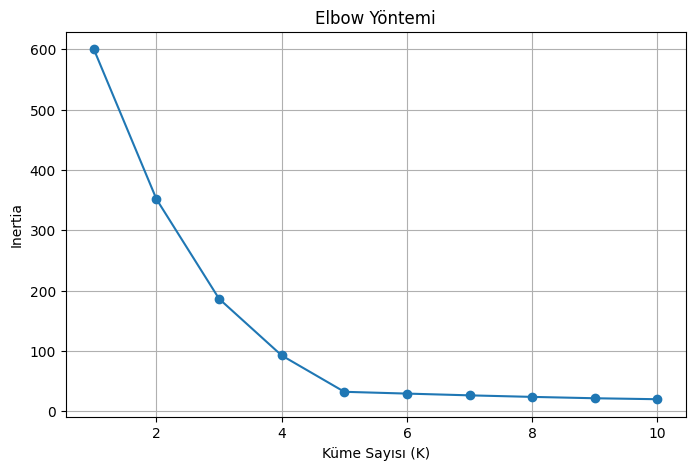


--- KÜMELEME ANALİZİ ---
Küme sayısı: 5
Silhouette skoru: 0.715

Küme merkezleri:
    yillik_gelir  harcama_puani
0  119952.383333      18.975000
1   23898.250000      74.910000
2  118735.666667      80.858333
3   25038.666667      25.716667
4   70796.216667      51.130000


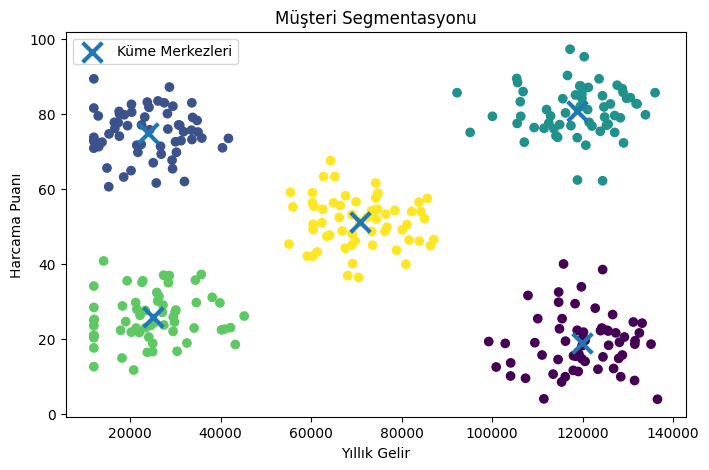


K-Means sonuçları sonuclar.txt dosyasına kaydedildi.


In [13]:
kumeleme_analizi()

**Duygu Analizi için fonksiyon tanımlama**

*   Veri Yükleme, Tokenizer ve pad sequences uygulanması
*   Eğitim ve test verilerinin ayrılması, Modelin eğitimi ve test aşamaları
*   Sonuçların ekrana yazdırılması ve sonuclar.txt dosyası içine yazma
---

IMDB film yorumlarından oluşan `IMDB Dataset.csv.zip` veri seti kullanılmıştır. Veri setinde 50.000 film yorumu bulunmaktadır.

Metin duygu analizi için SimpleRNN tabanlı bir derin öğrenme modeli kullanılmıştır.

Metinlerin işlenmesi aşamasında metinler `Tokenizer` ile sayısal dizilere dönüştürülmüştür. Diziler `maxlen=200` olacak şekilde `pad_sequences` ile eşit uzunluğa getirilmiştir.

Veri seti %80 eğitim ve %20 test olacak şekilde ayrılmıştır.

5 Epoch'luk bir eğitim yapılmıştır.










In [16]:
def duygu_analizi():
    # IMDB veri setini yükle
    imdb_df = pd.read_csv("IMDB Dataset.csv.zip")

    # Duygu etiketlerini sayısal hale getir
    y = (
        imdb_df["sentiment"] == "positive"
    ).astype(int).values

    # Metinleri sayısal dizilere dönüştür
    tokenizer = Tokenizer(num_words=10000)

    tokenizer.fit_on_texts(
        imdb_df["review"]
    )

    diziler = tokenizer.texts_to_sequences(
        imdb_df["review"]
    )

    X = pad_sequences(
        diziler,
        maxlen=200
    )

    # Eğitim ve test verilerine ayır
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    # SimpleRNN modeli
    model = Sequential([
        Embedding(
            input_dim=10000,
            output_dim=32),
        SimpleRNN(32),
        Dense(1, activation="sigmoid")
    ])

    # Modeli derle
    model.compile(
        loss="binary_crossentropy",
        optimizer="adam",
        metrics=["accuracy"]
    )

    # Modeli eğit
    model.fit(
        X_train,
        y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.2
    )

    # Test
    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test
    )

    print("\n--- METİN DUYGU ANALİZİ ---")
    print(f"Test kaybı: {test_loss:.4f}")
    print(f"Test doğruluğu: {test_accuracy:.4f}")
    print(f"Test doğruluğu (%): {test_accuracy * 100:.2f}")

    # Sonucu kaydet
    sonucu_kaydet(
        "SimpleRNN",
        "Test Accuracy",
        f"{test_accuracy:.4f}"
    )

    print(
        "SimpleRNN sonucu sonuclar.txt "
        "dosyasına kaydedildi."
    )

In [17]:
duygu_analizi()

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 51ms/step - accuracy: 0.6822 - loss: 0.5888 - val_accuracy: 0.6342 - val_loss: 0.6378
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 50ms/step - accuracy: 0.8021 - loss: 0.4345 - val_accuracy: 0.8434 - val_loss: 0.3652
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 49ms/step - accuracy: 0.8772 - loss: 0.3002 - val_accuracy: 0.8354 - val_loss: 0.4001
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 51ms/step - accuracy: 0.9110 - loss: 0.2301 - val_accuracy: 0.8494 - val_loss: 0.3809
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 26s 51ms/step - accuracy: 0.9488 - loss: 0.1470 - val_accuracy: 0.8249 - val_loss: 0.4362
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8301 - loss: 0.4175

--- METİN DUYGU ANALİZİ ---
Test kaybı: 0.4175
Test doğruluğu: 0.8301
Test doğruluğu (%): 83.01
SimpleRNN sonucu sonuclar.txt dosyasına kaydedildi.


**Görüntü Sınıflandırma için fonksiyon tanımlama**

*   Veri setini yükleme, Reshape ve Normalization işlemi
*   CNN modelinin kurulumu, eğitimi, test edilmesi
*   Sonuçların ekrana yazdırılması ve sonuclar.txt dosyası içine yazma
---

Görüntü sınıflandırma işlemi için Fashion-MNIST veri seti kullanılmıştır. Veri seti 28x28 piksel boyutunda gri tonlamalı giyim ürünü görüntülerinden oluşmaktadır.

Görüntülerin sınıflandırılması için Evrişimli Sinir Ağı (CNN) modeli kullanılmıştır.

10 Epoch'luk bir eğitim yapılmıştır.

Modelin performansı Test Loss ve Test Accuracy sonuçları ile değerlendirilmiştir.














In [18]:
def goruntu_siniflandirma():
    # Fashion-MNIST veri setini yükle
    (X_train, y_train), (X_test, y_test) = (
        tf.keras.datasets.fashion_mnist.load_data()
    )

    # Görüntüleri yeniden şekillendir ve normalize et
    X_train = X_train.reshape(
        -1, 28, 28, 1
    ).astype("float32") / 255.0

    X_test = X_test.reshape(
        -1, 28, 28, 1
    ).astype("float32") / 255.0

    # CNN modeli
    model = Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),

        Conv2D(
            32,
            (3, 3),
            activation="relu"
        ),
        MaxPooling2D((2, 2)),

        Conv2D(
            64,
            (3, 3),
            activation="relu"
        ),
        MaxPooling2D((2, 2)),

        Conv2D(
            128,
            (3, 3),
            activation="relu"
        ),
        MaxPooling2D((2, 2)),

        Flatten(),

        Dense(128, activation="relu"),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(10, activation="softmax")
    ])

    # Modeli derle
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Modeli eğit
    model.fit(
        X_train,
        y_train,
        epochs=10,
        batch_size=64,
        validation_data=(X_test, y_test)
    )

    # Test
    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test
    )

    print("\n--- GÖRÜNTÜ SINIFLANDIRMA ---")
    print(f"Test kaybı: {test_loss:.4f}")
    print(f"Test doğruluğu: {test_accuracy:.4f}")
    print(f"Test doğruluğu (%): {test_accuracy * 100:.2f}")

    # Sonucu kaydet
    sonucu_kaydet(
        "CNN",
        "Test Accuracy",
        f"{test_accuracy:.4f}"
    )

    print(
        "CNN sonucu sonuclar.txt dosyasına kaydedildi."
    )

In [19]:
goruntu_siniflandirma()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 63s 64ms/step - accuracy: 0.7547 - loss: 0.6600 - val_accuracy: 0.8290 - val_loss: 0.4730
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 60s 64ms/step - accuracy: 0.8417 - loss: 0.4320 - val_accuracy: 0.8455 - val_loss: 0.4167
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 63ms/step - accuracy: 0.8653 - loss: 0.3649 - val_accuracy: 0.8665 - val_loss: 0.3665
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 58s 61ms/step - accuracy: 0.8814 - loss: 0.3238 - val_accuracy: 0.8729 - val_loss: 0.3482
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 58s 62ms/step - accuracy: 0.8911 - loss: 0.2937 - val_accuracy: 0.8812 - val_loss: 0.3213
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 61s 65ms/step - accuracy: 0.9004 - loss: 0.2704 - val_accuracy: 0.8837 - val_loss: 0.3203
Epoch 7/10
938/938 ━━━━━━━━━━━━━

Menü arayüzü ile ilgili kod bloğu

İlgili menü seçimleri ile ilerlenerek modeller seçilebilir.

İşlem tamamlandıktan sonra Çıkış seçeneği ile blok sonlandırılır.

In [20]:
while True:
    print("\n" + "=" * 50)
    print("   BÜTÜNLEŞİK MAKİNE ÖĞRENMESİ UYGULAMASI")
    print("=" * 50)
    print("1 - Regresyon Analizi")
    print("2 - Kümeleme Analizi")
    print("3 - Metin Duygu Analizi")
    print("4 - Görüntü Sınıflandırma")
    print("5 - Çıkış")

    secim = input("\nSeçiminiz: ")

    if secim == "1":
        regresyon_analizi()

    elif secim == "2":
        kumeleme_analizi()

    elif secim == "3":
        duygu_analizi()

    elif secim == "4":
        goruntu_siniflandirma()

    elif secim == "5":
        print("\nProgram sonlandırıldı.")
        break

    else:
        print(
            "\nGeçersiz seçim. "
            "Lütfen 1-5 arasında bir değer girin."
        )


   BÜTÜNLEŞİK MAKİNE ÖĞRENMESİ UYGULAMASI
1 - Regresyon Analizi
2 - Kümeleme Analizi
3 - Metin Duygu Analizi
4 - Görüntü Sınıflandırma
5 - Çıkış

Seçiminiz: 5

Program sonlandırıldı.


**SONUÇ RAPORU**

Regresyon analizinde;
*   Sonuçlara göre MLP modeli en başarılı regresyon modeli olmuştur. En düşük MSE değeri 28551.11 ve en yüksek R² değeri 0.942 olarak MLP modelinde elde edilmiştir.

*   Doğrusal Regresyon ve Ridge birbirine oldukça yakın sonuçlar verirken, PCR diğer yöntemlere göre daha düşük performans göstermiştir. PLS ise PCR'a göre daha başarılı bir sonuç vermiştir.

Kümeleme analizinde;
*   Elde edilen 0.715 Silhouette Score değeri, müşterilerin oluşturulan 5 kümede birbirinden yeterli düzeyde ayrıldığını göstermektedir. K-Means yöntemi ile müşterilerin yıllık gelir ve harcama puanlarına göre anlamlı segmentlere ayrılabildiği görülmektedir.

Metin Duygu analizinde;
*   İlk çalıştırıldığında modelin test verisi %77.76 doğruluğunda olmuştur. Modelin değerleri değiştirilmeden tekrar çalıştırılması sonrası bu doğruluk artmıştır. sonuclar.txt dosyasında yer alan iki değerin kaydedilmesi ile durum kaydedilmiştir.
*   SimpleRNN modeli test verisinde elde edilen %83.01 doğruluk, modelin film yorumlarının olumlu veya olumsuz olduğunu başarılı bir şekilde sınıflandırabildiğini göstermektedir.

Görüntü Sınıflandırma analizinde;
*   CNN modeli Fashion-MNIST test verisinde %89.46 doğruluk elde etmiştir. Elde edilen sonuç, CNN modelinin görüntülerdeki özellikleri öğrenerek farklı giyim ürünü sınıflarını başarılı bir şekilde ayırt edebildiğini göstermektedir.



